# 04 - Evaluation, Visualization, and Error Analysis

This notebook evaluates the trained RF-DETR model on the **test split** and produces everything Section 4 and Section 5 of the report need: accuracy, precision, recall, IoU, mAP, per-class results, a confusion matrix, prediction visualizations, and error analysis.

The metric code is written from scratch (IoU function, Hungarian matching, TP/FP/FN counting) as the assignment asks, and mAP uses `pycocotools`. As a cross-check, the library's own evaluation is run at the end.

**How the metrics are defined**

1. For each test image, predictions with confidence at or above a threshold are kept.
2. Predicted and ground-truth boxes are matched one-to-one with the Hungarian algorithm on IoU. A pair counts as matched only if IoU is at least 0.5.
3. A matched pair with the correct class is a **true positive (TP)**. A matched pair with the wrong class counts as one **false positive (FP)** and one **false negative (FN)**. An unmatched prediction is an FP, and an unmatched ground-truth box is an FN.
4. Precision = TP / (TP + FP). Recall = TP / (TP + FN).
5. **Classification accuracy** = correctly classified matched pairs / all matched pairs (the "accuracy after Hungarian matching" from the assignment).
6. **mAP** is computed over all confidence levels, so it does not depend on a threshold. The confidence threshold for precision and recall is chosen on the **validation** split (best F1), then applied unchanged to the test split, so the test set is never used for tuning.

## 0. Setup

In [1]:
!pip install -q "rfdetr[train,augment]" tensorboard pycocotools supervision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.7/604.7 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 406.3/406.3 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 678.2/678.2 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [2]:
import os, json, glob, time, copy, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from scipy.optimize import linear_sum_assignment
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

from google.colab import drive
drive.mount("/content/drive")

pd.set_option("display.width", 170)
plt.rcParams["figure.dpi"] = 110

Mounted at /content/drive


In [3]:
# ---------- CONFIG: edit these ----------
PROJECT_DIR = "/content/drive/MyDrive/rf-detr-trash"      # same folder used in notebook 03
DATA_DIR    = "/content/trash-clean"                       # cleaned dataset
RUN_NAME    = "exp_a_baseline_noaug"                         # which experiment to evaluate (folder name under runs/)
IOU_THR     = 0.5                                          # IoU needed to call a prediction a match
LOW_CONF    = 0.001                                        # keep nearly all predictions so mAP is not truncated

CKPT        = f"{PROJECT_DIR}/runs/{RUN_NAME}/checkpoint_best_total.pth"
RESULTS_DIR = f"{PROJECT_DIR}/results/{RUN_NAME}"
FIG_DIR     = f"{RESULTS_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Restore the cleaned dataset from Drive if this is a fresh Colab runtime
if not os.path.exists(f"{DATA_DIR}/test/_annotations.coco.json"):
    zpath = f"{PROJECT_DIR}/trash-clean.zip"
    assert os.path.exists(zpath), "Cleaned dataset not found. Run notebook 02 and 03 first."
    with zipfile.ZipFile(zpath) as z:
        z.extractall(os.path.dirname(DATA_DIR))
assert os.path.exists(CKPT), f"Checkpoint not found: {CKPT}. Check RUN_NAME."

def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=170, bbox_inches="tight")
print("Checkpoint:", CKPT)
print("Results will be saved to:", RESULTS_DIR)
import torch
print("Device:", "GPU - " + torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "CPU (slow! Runtime > Change runtime type > T4 GPU, then run again)")

Checkpoint: /content/drive/MyDrive/rf-detr-trash/runs/exp_a_baseline_noaug/checkpoint_best_total.pth
Results will be saved to: /content/drive/MyDrive/rf-detr-trash/results/exp_a_baseline_noaug
Device: CPU (slow! Runtime > Change runtime type > T4 GPU, then run again)


## 1. Load ground truth

**What this step does.** Reads the cleaned COCO annotations for the validation and test splits and converts boxes to `[x1, y1, x2, y2]`. The printed counts (images, boxes) should match `dataset_info.json` from notebook 02. If they do not, the wrong dataset folder was restored.

In [4]:
def load_coco(split):
    with open(f"{DATA_DIR}/{split}/_annotations.coco.json") as f:
        return json.load(f)

GT_JSON = {s: load_coco(s) for s in ["valid", "test"]}
CLASS_NAMES = [c["name"] for c in sorted(GT_JSON["test"]["categories"], key=lambda c: c["id"])]
K = len(CLASS_NAMES)
assert [c["id"] for c in sorted(GT_JSON["test"]["categories"], key=lambda c: c["id"])] == list(range(K)), \
    "Category ids must be 0..K-1. Re-run notebook 02 (cleaning)."

def build_gt_index(coco_dict):
    """image_id -> dict(file, w, h, boxes[N,4] in xyxy pixels, labels[N])."""
    out = {im["id"]: dict(file=im["file_name"], w=im["width"], h=im["height"], boxes=[], labels=[])
           for im in coco_dict["images"]}
    for a in coco_dict["annotations"]:
        x, y, w, h = a["bbox"]
        out[a["image_id"]]["boxes"].append([x, y, x + w, y + h])
        out[a["image_id"]]["labels"].append(a["category_id"])
    for v in out.values():
        v["boxes"] = np.array(v["boxes"], dtype=float).reshape(-1, 4)
        v["labels"] = np.array(v["labels"], dtype=int)
    return out

GT = {s: build_gt_index(GT_JSON[s]) for s in GT_JSON}
print("Classes:", CLASS_NAMES)
print({s: (len(GT[s]), int(sum(len(v['labels']) for v in GT[s].values()))) for s in GT}, "(images, boxes)")

Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
{'valid': (379, 383), 'test': (377, 382)} (images, boxes)


## 2. Metric code

`iou_xyxy` is the IoU function required by the assignment. `iou_matrix` is the same computation vectorized for speed. `match_image` does the Hungarian matching. `evaluate_at` turns matches into TP, FP, FN, accuracy, a confusion matrix, and a list of every error. `coco_map` wraps `pycocotools`.

**Why from scratch.** The assignment asks for our own IoU and matching, so these functions do not use the library's metrics. The Hungarian step guarantees one prediction per true box, so a duplicate box counts as a false positive instead of inflating recall. Accuracy is measured after matching, so it only judges the class of boxes that were localized.

In [5]:
def iou_xyxy(a, b):
    """IoU of two boxes given as [x1, y1, x2, y2]."""
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def iou_matrix(A, B):
    """Pairwise IoU between boxes A[N,4] and B[M,4] (xyxy). Returns an [N, M] array."""
    A = np.asarray(A, dtype=float).reshape(-1, 4)
    B = np.asarray(B, dtype=float).reshape(-1, 4)
    if len(A) == 0 or len(B) == 0:
        return np.zeros((len(A), len(B)))
    ix1 = np.maximum(A[:, None, 0], B[None, :, 0]); iy1 = np.maximum(A[:, None, 1], B[None, :, 1])
    ix2 = np.minimum(A[:, None, 2], B[None, :, 2]); iy2 = np.minimum(A[:, None, 3], B[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (A[:, 2] - A[:, 0]) * (A[:, 3] - A[:, 1])
    area_b = (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1])
    union = area_a[:, None] + area_b[None, :] - inter
    return np.where(union > 0, inter / np.maximum(union, 1e-12), 0.0)


def match_image(gt_boxes, pr_boxes, iou_thr=0.5):
    """One-to-one Hungarian matching on IoU (class-agnostic).
    Pairs below iou_thr are not allowed. Returns (pairs, unmatched_gt, unmatched_pred, iou_matrix)."""
    iou = iou_matrix(gt_boxes, pr_boxes)
    pairs = []
    if iou.size:
        cost = np.where(iou >= iou_thr, iou, 0.0)       # forbid sub-threshold pairs
        rows, cols = linear_sum_assignment(-cost)       # maximise total IoU
        pairs = [(int(r), int(c), float(iou[r, c])) for r, c in zip(rows, cols) if iou[r, c] >= iou_thr]
    mg = {p[0] for p in pairs}
    mp = {p[1] for p in pairs}
    un_g = [i for i in range(len(gt_boxes)) if i not in mg]
    un_p = [j for j in range(len(pr_boxes)) if j not in mp]
    return pairs, un_g, un_p, iou


def _safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def evaluate_at(gt_idx, preds, conf_thr, K, iou_thr=0.5):
    """Detection metrics at one confidence threshold.

    gt_idx : image_id -> dict(boxes, labels, w, h, file)
    preds  : image_id -> dict(boxes[N,4], scores[N], labels[N])
    """
    cm = np.zeros((K + 1, K + 1), dtype=int)      # rows: true class (K = background), cols: predicted (K = background)
    tp_c = np.zeros(K, int); fp_c = np.zeros(K, int); fn_c = np.zeros(K, int)
    n_matched = n_correct = 0
    ious, errors, gt_rows = [], [], []

    for img_id, g in gt_idx.items():
        p = preds.get(img_id)
        if p is None:
            pb, ps, pl = np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)
        else:
            keep = p["scores"] >= conf_thr
            pb, ps, pl = p["boxes"][keep], p["scores"][keep], p["labels"][keep]

        pairs, un_g, un_p, iou = match_image(g["boxes"], pb, iou_thr)
        img_area = g["w"] * g["h"]

        for gi, pj, v in pairs:
            gl, pc = int(g["labels"][gi]), int(pl[pj])
            cm[gl, pc] += 1; n_matched += 1; ious.append(v)
            rel = float((g["boxes"][gi][2] - g["boxes"][gi][0]) * (g["boxes"][gi][3] - g["boxes"][gi][1]) / img_area)
            if gl == pc:
                n_correct += 1; tp_c[gl] += 1
                gt_rows.append(dict(image_id=img_id, gt=gl, outcome="correct", iou=v, score=float(ps[pj]), rel_area=rel))
            else:
                fn_c[gl] += 1; fp_c[pc] += 1
                errors.append(dict(image_id=img_id, type="wrong_class", gt=gl, pred=pc, score=float(ps[pj]), iou=v, gi=gi, pj=pj))
                gt_rows.append(dict(image_id=img_id, gt=gl, outcome="wrong_class", iou=v, score=float(ps[pj]), rel_area=rel))
        for gi in un_g:
            gl = int(g["labels"][gi])
            cm[gl, K] += 1; fn_c[gl] += 1
            best = float(iou[gi].max()) if iou.shape[1] else 0.0
            rel = float((g["boxes"][gi][2] - g["boxes"][gi][0]) * (g["boxes"][gi][3] - g["boxes"][gi][1]) / img_area)
            errors.append(dict(image_id=img_id, type="missed", gt=gl, pred=-1, score=0.0, iou=best, gi=gi, pj=-1))
            gt_rows.append(dict(image_id=img_id, gt=gl, outcome="missed", iou=best, score=0.0, rel_area=rel))
        for pj in un_p:
            pc = int(pl[pj])
            cm[K, pc] += 1; fp_c[pc] += 1
            best = float(iou[:, pj].max()) if iou.shape[0] else 0.0
            errors.append(dict(image_id=img_id, type="false_positive", gt=-1, pred=pc, score=float(ps[pj]), iou=best, gi=-1, pj=pj))

    TP, FP, FN = int(tp_c.sum()), int(fp_c.sum()), int(fn_c.sum())
    prec, rec = _safe_div(TP, TP + FP), _safe_div(TP, TP + FN)
    f1 = _safe_div(2 * prec * rec, prec + rec)

    per_class = pd.DataFrame({
        "class": CLASS_NAMES,
        "support": cm[:K].sum(axis=1),
        "TP": tp_c, "FP": fp_c, "FN": fn_c,
        "precision": [_safe_div(tp_c[c], tp_c[c] + fp_c[c]) for c in range(K)],
        "recall": [_safe_div(tp_c[c], tp_c[c] + fn_c[c]) for c in range(K)],
    })
    per_class["f1"] = [_safe_div(2 * r.precision * r.recall, r.precision + r.recall) for r in per_class.itertuples()]

    return dict(conf_thr=conf_thr, TP=TP, FP=FP, FN=FN, precision=prec, recall=rec, f1=f1,
                cls_accuracy=_safe_div(n_correct, n_matched), n_matched=n_matched, n_gt=int(cm[:K].sum()),
                mean_iou=float(np.mean(ious)) if ious else 0.0, confusion=cm, per_class=per_class,
                errors=pd.DataFrame(errors), gt_rows=pd.DataFrame(gt_rows))


def sweep_thresholds(gt_idx, preds, thresholds, K, iou_thr=0.5):
    rows = []
    for t in thresholds:
        r = evaluate_at(gt_idx, preds, float(t), K, iou_thr)
        rows.append(dict(conf_thr=float(t), precision=r["precision"], recall=r["recall"], f1=r["f1"],
                         cls_accuracy=r["cls_accuracy"], TP=r["TP"], FP=r["FP"], FN=r["FN"]))
    return pd.DataFrame(rows)


def coco_map(gt_dict, preds, K, max_dets=100):
    """COCO-style mAP with pycocotools. Returns overall numbers and per-class AP."""
    gtd = copy.deepcopy(gt_dict)
    # pycocotools treats annotation id 0 as "unmatched" internally, and Roboflow exports can start ids at 0,
    # which would silently drop one ground-truth box from the score. Renumber from 1 to be safe.
    for n, a in enumerate(gtd["annotations"], start=1):
        a["id"] = n
        a.setdefault("iscrowd", 0)
        a.setdefault("area", a["bbox"][2] * a["bbox"][3])
    gtd.setdefault("info", {}); gtd.setdefault("licenses", [])
    coco_gt = COCO(); coco_gt.dataset = gtd; coco_gt.createIndex()

    dets = []
    for img_id, p in preds.items():
        for k in np.argsort(-p["scores"])[:max_dets]:
            x1, y1, x2, y2 = [float(v) for v in p["boxes"][k]]
            dets.append(dict(image_id=int(img_id), category_id=int(p["labels"][k]),
                             bbox=[x1, y1, x2 - x1, y2 - y1], score=float(p["scores"][k])))
    if not dets:
        z = np.zeros(K)
        return dict(mAP_50_95=0.0, mAP_50=0.0, mAP_75=0.0, AR_100=0.0, ap50_per_class=z, ap_per_class=z, E=None)

    coco_dt = coco_gt.loadRes(dets)
    E = COCOeval(coco_gt, coco_dt, "bbox")
    E.evaluate(); E.accumulate(); E.summarize()

    prec = E.eval["precision"]                       # [T, R, K, A, M]
    ap50_c, ap_c = [], []
    for k in range(prec.shape[2]):
        p50 = prec[0, :, k, 0, -1]; p_all = prec[:, :, k, 0, -1]
        ap50_c.append(float(p50[p50 > -1].mean()) if (p50 > -1).any() else 0.0)
        ap_c.append(float(p_all[p_all > -1].mean()) if (p_all > -1).any() else 0.0)
    return dict(mAP_50_95=float(E.stats[0]), mAP_50=float(E.stats[1]), mAP_75=float(E.stats[2]),
                AR_100=float(E.stats[8]), ap50_per_class=np.array(ap50_c), ap_per_class=np.array(ap_c), E=E)

## 3. Load the trained model and predict on valid and test

Predictions are kept down to a very low confidence (`LOW_CONF`) so mAP sees the full ranking. Precision and recall use a higher threshold chosen in the next section. The model's class order comes from the training dataset, which is the cleaned one, so it matches `CLASS_NAMES`. The code maps predictions by class name when the model provides names, as a safety check.

**What this step does.** Loads the best checkpoint of the selected run and predicts on every validation and test image at confidence 0.001. This is the slowest cell of the notebook (about 1 to 3 minutes on a T4 GPU, many times longer on CPU). The final line prints how many boxes the model keeps per image at this threshold (a few hundred is normal for a DETR model with 300 queries). The check at the end of the cell fails if any image is missing from the results.

In [6]:
from rfdetr import RFDETR

model = RFDETR.from_checkpoint(CKPT)
print("Model class      :", type(model).__name__)
print("Classes in model :", model.class_names)
assert list(model.class_names) == CLASS_NAMES, (
    "Class order in the checkpoint differs from the dataset. Do not continue until this is resolved.")

/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-14 18:19:51] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 18:19:51] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

Model class      : RFDETRNano
Classes in model : ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [7]:
def predict_split(model, split, conf=LOW_CONF, batch=16):
    """Run the model on every image of a split. Returns image_id -> dict(boxes, scores, labels)."""
    items = list(GT[split].items())
    preds = {}
    for s in range(0, len(items), batch):
        chunk = items[s:s + batch]
        imgs = [Image.open(f"{DATA_DIR}/{split}/{g['file']}").convert("RGB") for _, g in chunk]
        dets = model.predict(imgs, threshold=conf)
        if not isinstance(dets, list):
            dets = [dets]
        for (img_id, _), d in zip(chunk, dets):
            boxes = np.asarray(d.xyxy, dtype=float).reshape(-1, 4)
            scores = np.asarray(d.confidence if d.confidence is not None else np.ones(len(boxes)), dtype=float)
            names = d.data.get("class_name") if getattr(d, "data", None) else None
            if names is not None and len(names):
                # The model has an extra "__background__" output slot. At a very low
                # threshold it can show up, so keep only detections of our real classes.
                keep = np.array([str(n) in CLASS_NAMES for n in names], dtype=bool)
                labels = np.array([CLASS_NAMES.index(str(n)) for n in names if str(n) in CLASS_NAMES], dtype=int)
                boxes, scores = boxes[keep], scores[keep]
            else:
                labels = np.asarray(d.class_id, dtype=int)
            preds[img_id] = dict(boxes=boxes, scores=scores, labels=labels)
    # Safety check: every image must have an entry (a wrong indent once kept only 1 image per batch)
    assert len(preds) == len(items), f"Only {len(preds)} of {len(items)} images have predictions"
    return preds

t0 = time.time()
PRED = {"valid": predict_split(model, "valid"), "test": predict_split(model, "test")}
print(f"Predicted {len(PRED['valid'])} valid + {len(PRED['test'])} test images in {time.time()-t0:.0f}s")
print("Avg detections per image at conf >= 0.001:", np.mean([len(p['scores']) for p in PRED['test'].values()]).round(1))

[2026-10-14 18:19:52] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Predicted 379 valid + 377 test images in 490s
Avg detections per image at conf >= 0.001: 293.1


## 4. Choose the confidence threshold on the validation split

The threshold that gives the best F1 on **validation** is used for the test numbers. This avoids tuning on the test set.

**How to read it.** Low thresholds keep many boxes, so recall is high and precision is lower. High thresholds do the opposite. F1 balances the two, and the peak of the curve is the threshold used for the test set. The choice is made on validation only, so the test results are not tuned to the test set. A flat F1 curve means the model is not sensitive to this choice.

,conf_thr,precision,recall,f1,cls_accuracy,TP,FP,FN
0,0.05,0.382,0.901,0.537,0.908,345,557,38
1,0.10,0.648,0.909,0.757,0.916,348,189,35
2,0.15,0.744,0.911,0.819,0.918,349,120,34
3,0.20,0.793,0.911,0.848,0.918,349,91,34
4,0.25,0.813,0.909,0.858,0.918,348,80,35
5,0.30,0.829,0.909,0.867,0.918,348,72,35
6,0.35,0.849,0.909,0.878,0.918,348,62,35
7,0.40,0.866,0.909,0.887,0.921,348,54,35
8,0.45,0.879,0.909,0.893,0.921,348,48,35
9,0.50,0.904,0.906,0.905,0.930,347,37,36


Best validation F1 = 0.915 at confidence threshold 0.7


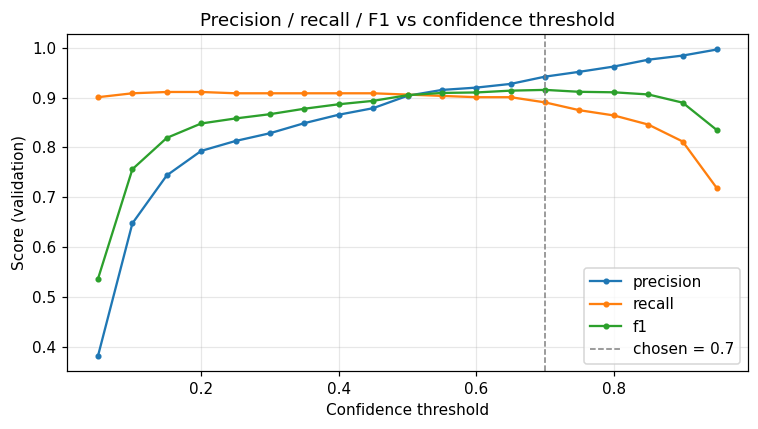

In [8]:
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.05), 2)
sweep_val = sweep_thresholds(GT["valid"], PRED["valid"], THRESHOLDS, K, IOU_THR)
best_row = sweep_val.loc[sweep_val["f1"].idxmax()]
BEST_THR = float(best_row["conf_thr"])
display(sweep_val.round(3))
print(f"Best validation F1 = {best_row['f1']:.3f} at confidence threshold {BEST_THR}")

fig, ax = plt.subplots(figsize=(7, 4))
for col in ["precision", "recall", "f1"]:
    ax.plot(sweep_val["conf_thr"], sweep_val[col], marker="o", ms=3, label=col)
ax.axvline(BEST_THR, color="gray", ls="--", lw=1, label=f"chosen = {BEST_THR}")
ax.set_xlabel("Confidence threshold"); ax.set_ylabel("Score (validation)")
ax.set_title("Precision / recall / F1 vs confidence threshold"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); savefig("threshold_sweep"); plt.show()

## 5. Test-set results

The main table uses the validation-selected threshold. A second row at the common default of 0.5 is shown for comparison.

**How to read it.** The first table is the threshold-based result (accuracy, precision, recall, F1, mean IoU). The second table is threshold-free (mAP) and is the main headline number for detection. Accuracy near precision means most localized boxes get the right class. Recall below precision means the model misses objects rather than inventing them. Mean IoU shows how tightly the boxes fit.

In [9]:
RES = evaluate_at(GT["test"], PRED["test"], BEST_THR, K, IOU_THR)
RES_05 = evaluate_at(GT["test"], PRED["test"], 0.5, K, IOU_THR)
MAP = coco_map(GT_JSON["test"], PRED["test"], K)

summary = pd.DataFrame([
    dict(setting=f"conf >= {BEST_THR} (chosen on valid)", accuracy=RES["cls_accuracy"], precision=RES["precision"],
         recall=RES["recall"], f1=RES["f1"], mean_IoU=RES["mean_iou"], TP=RES["TP"], FP=RES["FP"], FN=RES["FN"]),
    dict(setting="conf >= 0.5 (default)", accuracy=RES_05["cls_accuracy"], precision=RES_05["precision"],
         recall=RES_05["recall"], f1=RES_05["f1"], mean_IoU=RES_05["mean_iou"], TP=RES_05["TP"], FP=RES_05["FP"], FN=RES_05["FN"]),
])
print("TEST SET: threshold-based metrics (IoU >= %.2f)" % IOU_THR)
display(summary.round(4))

print("TEST SET: threshold-free metrics (pycocotools)")
display(pd.DataFrame([dict(mAP_50=MAP["mAP_50"], mAP_75=MAP["mAP_75"], mAP_50_95=MAP["mAP_50_95"], AR_100=MAP["AR_100"])]).round(4))

creating index...
index created!
Loading and preparing results...
DONE (t=0.05s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.83s).
Accumulating evaluation results...
DONE (t=0.63s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.924
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.953
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.942
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.494
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.925
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.966
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.985
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.987
 Average Recall     (AR) @[ IoU=0.

,setting,accuracy,precision,recall,f1,mean_IoU,TP,FP,FN
0,conf >= 0.7 (chosen on valid),0.956,0.9560,0.9110,0.9330,0.9709,348,16,34
1,conf >= 0.5 (default),0.939,0.9267,0.9267,0.9267,0.9699,354,28,28


TEST SET: threshold-free metrics (pycocotools)


,mAP_50,mAP_75,mAP_50_95,AR_100
0,0.9532,0.9417,0.9236,0.9866


TEST SET: per-class results (support = number of test boxes)


,class,support,TP,FP,FN,precision,recall,f1,AP_50,AP_50_95
0,cardboard,55,52,0,3,1.000,0.945,0.972,0.964,0.933
1,glass,89,81,6,8,0.931,0.910,0.920,0.985,0.976
2,metal,54,50,7,4,0.877,0.926,0.901,0.961,0.930
3,paper,86,79,0,7,1.000,0.919,0.958,0.972,0.966
4,plastic,83,75,0,8,1.000,0.904,0.949,0.984,0.892
5,trash,15,11,3,4,0.786,0.733,0.759,0.852,0.845


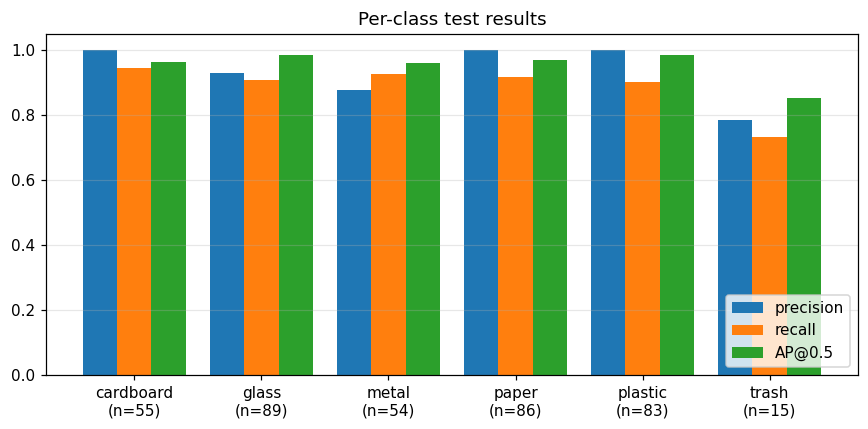

In [10]:
per_class = RES["per_class"].copy()
per_class["AP_50"] = MAP["ap50_per_class"]
per_class["AP_50_95"] = MAP["ap_per_class"]
print("TEST SET: per-class results (support = number of test boxes)")
display(per_class.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(K); w = 0.27
ax.bar(x - w, per_class["precision"], w, label="precision")
ax.bar(x,     per_class["recall"],    w, label="recall")
ax.bar(x + w, per_class["AP_50"],     w, label="AP@0.5")
ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n={s})" for c, s in zip(per_class["class"], per_class["support"])])
ax.set_ylim(0, 1.05); ax.set_title("Per-class test results"); ax.legend(loc="lower right"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); savefig("per_class_results"); plt.show()

### Confusion matrix

The last row and column (`none`) show missed objects (true box with no matching prediction) and false detections (prediction with no true box).

**How to read it.** Rows are true classes and columns are predictions. Large off-diagonal cells are class confusions, and the `none` row and column are misses and false detections. For the report, name the one or two biggest confusions and say why the classes look alike.

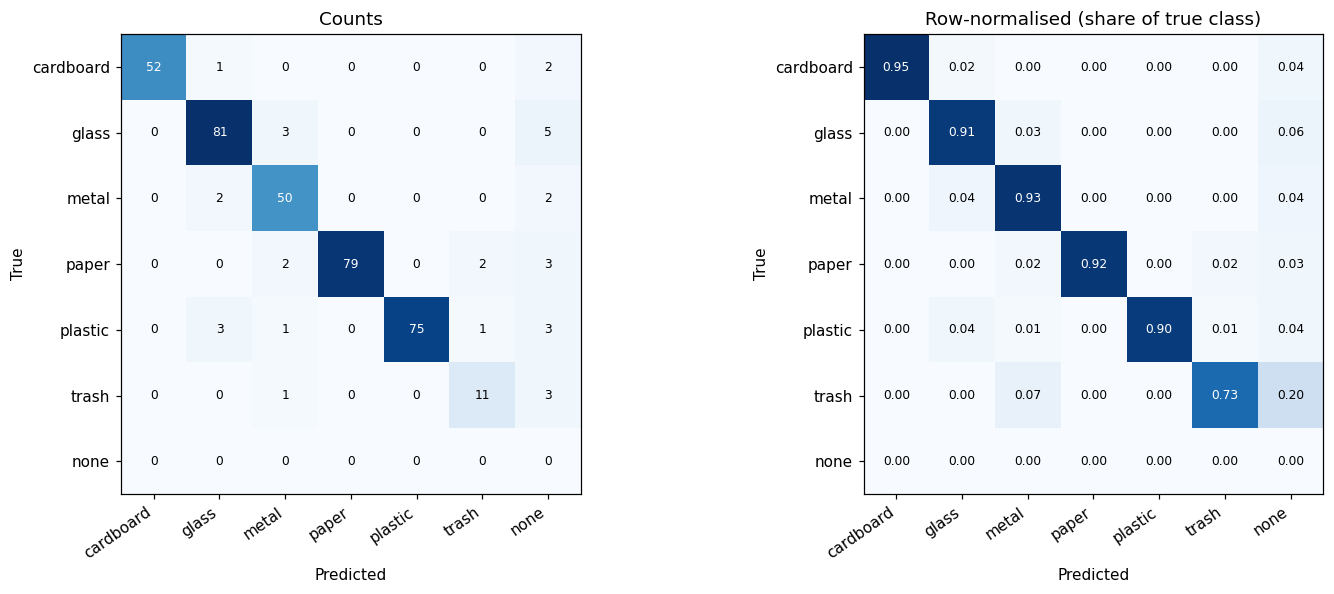

In [11]:
labels = CLASS_NAMES + ["none"]
cm = RES["confusion"]
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, M, title, fmt in [(axes[0], cm, "Counts", "d"), (axes[1], cm_norm, "Row-normalised (share of true class)", ".2f")]:
    im = ax.imshow(M, cmap="Blues")
    ax.set_xticks(range(K + 1)); ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticks(range(K + 1)); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    for i in range(K + 1):
        for j in range(K + 1):
            v = M[i, j]
            ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=8,
                    color="white" if v > M.max() * 0.55 else "black")
plt.tight_layout(); savefig("confusion_matrix"); plt.show()

### Precision-recall curves (IoU 0.5)

**How to read it.** A curve that stays near 1 until high recall means the class is detected reliably. The area under each curve is that class's AP.

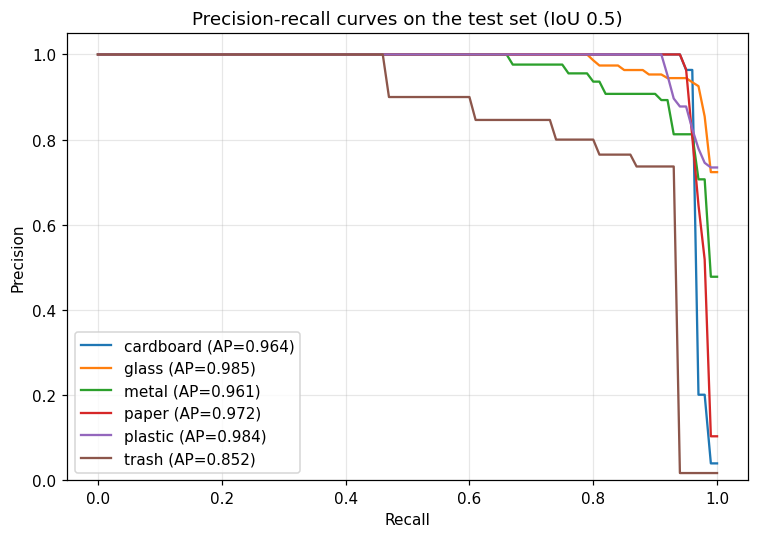

In [12]:
E = MAP["E"]
if E is not None:
    rec_thrs = E.params.recThrs
    fig, ax = plt.subplots(figsize=(7, 5))
    for k, name in enumerate(CLASS_NAMES):
        pr = E.eval["precision"][0, :, k, 0, -1]
        ax.plot(rec_thrs, np.where(pr > -1, pr, np.nan), label=f"{name} (AP={MAP['ap50_per_class'][k]:.3f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.05)
    ax.set_title("Precision-recall curves on the test set (IoU 0.5)"); ax.legend(loc="lower left"); ax.grid(alpha=.3)
    plt.tight_layout(); savefig("pr_curves"); plt.show()

### Cross-check with the library's own evaluation

The library computes mAP with its own COCO evaluator. The numbers should agree closely with the `pycocotools` values above. Small differences can come from how the library sets the prediction limit and resizes images. If this cell errors on your version, skip it, because the numbers above are the ones to report.

**Why it matters.** This is an independent check of our own mAP. The library also resizes images and uses its own evaluator, so a small difference is expected. A large difference means a bug in our matching or in how predictions were collected. It runs the model on the full test split, so it is also slow on CPU.

In [13]:
try:
    lib = model.evaluate(split="test", dataset_dir=DATA_DIR, batch_size=8, num_workers=2, output_dir=f"{RESULTS_DIR}/lib_eval")
    print({k: round(float(v), 4) for k, v in lib.items() if not k.startswith("test/AP/")})
    print(f"\nOwn pycocotools: mAP50={MAP['mAP_50']:.4f}  mAP50-95={MAP['mAP_50_95']:.4f}")
except Exception as e:
    print("Library evaluation skipped:", type(e).__name__, e)

[2026-10-14 18:28:12] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-14 18:28:12] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-14 18:28:13] [INFO] rf-detr - Building Roboflow test dataset with square resize at resolution 384
[2026-10-14 18:28:13] [INFO] rf-detr - Using multi-scale training with square resize and scales: [544]


INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          test/F1          │    0.9208540320396423     │
│         test/loss         │    1.8307708501815796     │
│        test/mAP_50        │    0.9515480995178223     │
│      test/mAP_50_95       │    0.9215583205223083     │
│        test/mAP_75        │    0.9397575855255127     │
│         test/mAR          │    0.9885750412940979     │
│      test/precision       │    0.9115846753120422     │
│        test/recall        │    0.9331499338150024     │
└───────────────────────────┴───────────────────────────┘

{'test/loss': 1.8308, 'test/mAP_50_95': 0.9216, 'test/mAP_50': 0.9515, 'test/mAP_75': 0.9398, 'test/mAR': 0.9886, 'test/F1': 0.9209, 'test/precision': 0.9116, 'test/recall': 0.9331}

Own pycocotools: mAP50=0.9532  mAP50-95=0.9236


## 6. Visualizing predictions

Green dashed boxes are ground truth. Solid colored boxes are predictions at the chosen threshold, labeled with class and confidence.

**How to read it.** Compare the dashed green truth with the solid predicted box. Random samples show typical behavior, and the per-class figure shows the model at its best. Use both in the report so the figures are not cherry-picked.

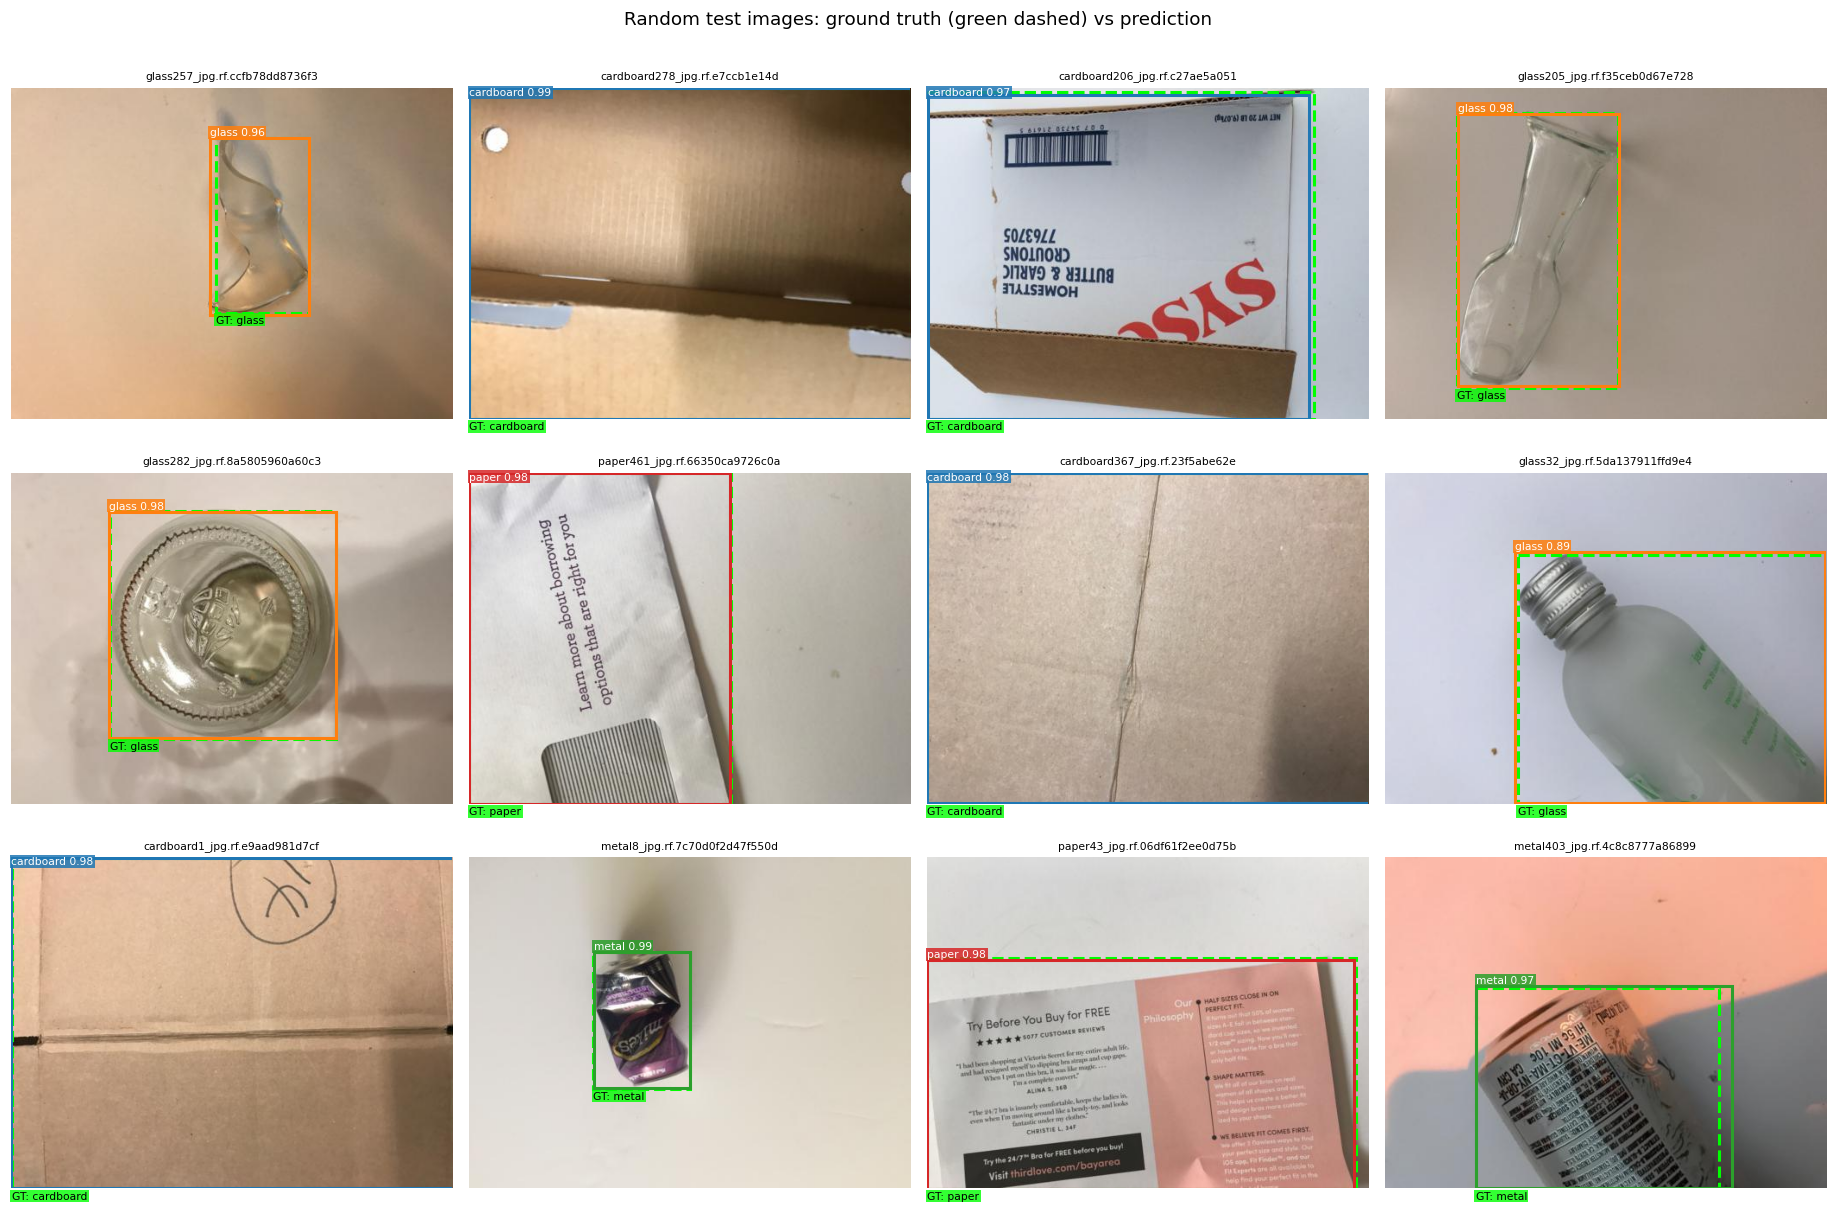

In [14]:
PALETTE = plt.cm.tab10(np.linspace(0, 1, 10))
def color(c): return PALETTE[c % 10]

def draw_cases(split, image_ids, conf_thr, cols=4, title=None, savename=None):
    image_ids = list(image_ids)
    if not image_ids:
        print("Nothing to draw."); return
    rows = int(np.ceil(len(image_ids) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.7 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, iid in zip(axes, image_ids):
        g, p = GT[split][iid], PRED[split].get(iid)
        ax.imshow(Image.open(f"{DATA_DIR}/{split}/{g['file']}").convert("RGB"))
        for b, l in zip(g["boxes"], g["labels"]):
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="lime", lw=2, ls="--"))
            ax.text(b[0], b[3] + 12, f"GT: {CLASS_NAMES[l]}", color="black", fontsize=7,
                    bbox=dict(fc="lime", alpha=.8, pad=1, ec="none"))
        if p is not None:
            for b, s, l in zip(p["boxes"], p["scores"], p["labels"]):
                if s < conf_thr: continue
                ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec=color(l), lw=2))
                ax.text(b[0], max(b[1] - 3, 8), f"{CLASS_NAMES[l]} {s:.2f}", color="white", fontsize=7,
                        bbox=dict(fc=color(l), alpha=.85, pad=1, ec="none"))
        ax.set_title(g["file"][:30], fontsize=7)
    if title: fig.suptitle(title, y=1.0, fontsize=12)
    plt.tight_layout()
    if savename: savefig(savename)
    plt.show()

rng = random.Random(7)
sample_ids = rng.sample(list(GT["test"].keys()), 12)
draw_cases("test", sample_ids, BEST_THR, title="Random test images: ground truth (green dashed) vs prediction", savename="predictions_random")

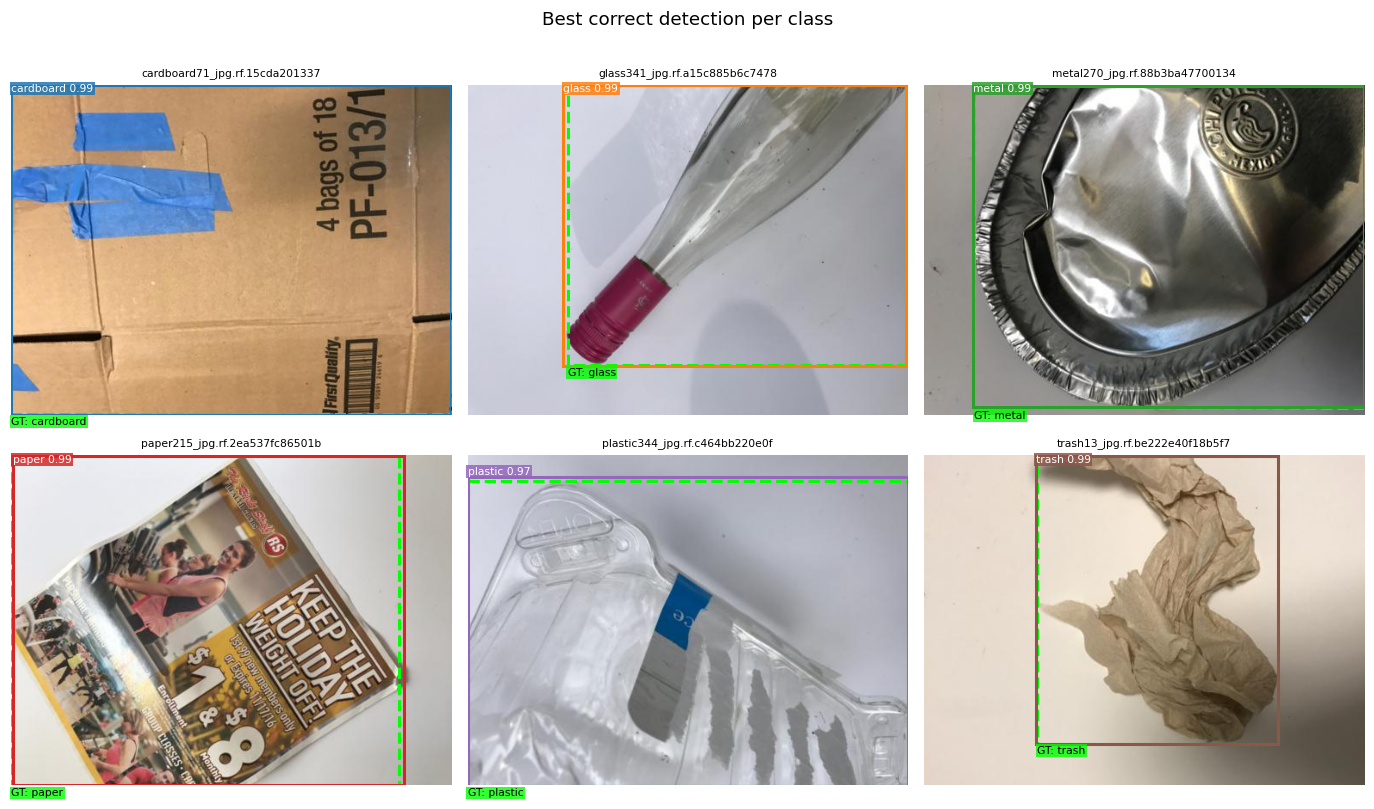

In [15]:
# One example per class (the most confident correct detection of each class), good for the report
correct = RES["gt_rows"][RES["gt_rows"]["outcome"] == "correct"].sort_values("score", ascending=False)
per_class_ids = [int(correct[correct["gt"] == c].iloc[0]["image_id"]) for c in range(K) if (correct["gt"] == c).any()]
draw_cases("test", per_class_ids, BEST_THR, cols=3, title="Best correct detection per class", savename="predictions_per_class")

## 7. Error analysis

Every error is one of three types: **wrong class** (box found, class wrong), **missed** (true object without a matching prediction), or **false positive** (prediction with no true object, for example a duplicate box or a hallucinated detection).

**How to read it.** The counts by type show whether the model mostly confuses classes, misses objects, or invents them. The most common confusions list names the class pairs to discuss. The error galleries show example images for each type, which is what to describe in the Discussion section.

In [16]:
errs = RES["errors"]
if len(errs):
    errs = errs.copy()
    errs["gt_name"] = errs["gt"].map(lambda i: CLASS_NAMES[i] if i >= 0 else "-")
    errs["pred_name"] = errs["pred"].map(lambda i: CLASS_NAMES[i] if i >= 0 else "-")
    print("Error counts by type:")
    display(errs["type"].value_counts().to_frame("count"))
else:
    print("No errors at this threshold.")

print(f"Total test objects: {RES['n_gt']} | correct: {RES['TP']} | accuracy after matching: {RES['cls_accuracy']:.4f}")

Error counts by type:


,count
type,
missed,18
wrong_class,16


Total test objects: 382 | correct: 348 | accuracy after matching: 0.9560


In [17]:
# Most common class confusions (matched box, wrong class)
if len(errs) and (errs["type"] == "wrong_class").any():
    conf_pairs = (errs[errs["type"] == "wrong_class"].groupby(["gt_name", "pred_name"]).size()
                  .sort_values(ascending=False).rename("count").to_frame())
    print("Most frequent confusions (true -> predicted):")
    display(conf_pairs.head(10))

Most frequent confusions (true -> predicted):


count
gt_name   pred_name       
glass     metal          3
plastic   glass          3
paper     trash          2
          metal          2
metal     glass          2
cardboard glass          1
plastic   metal          1
          trash          1
trash     metal          1

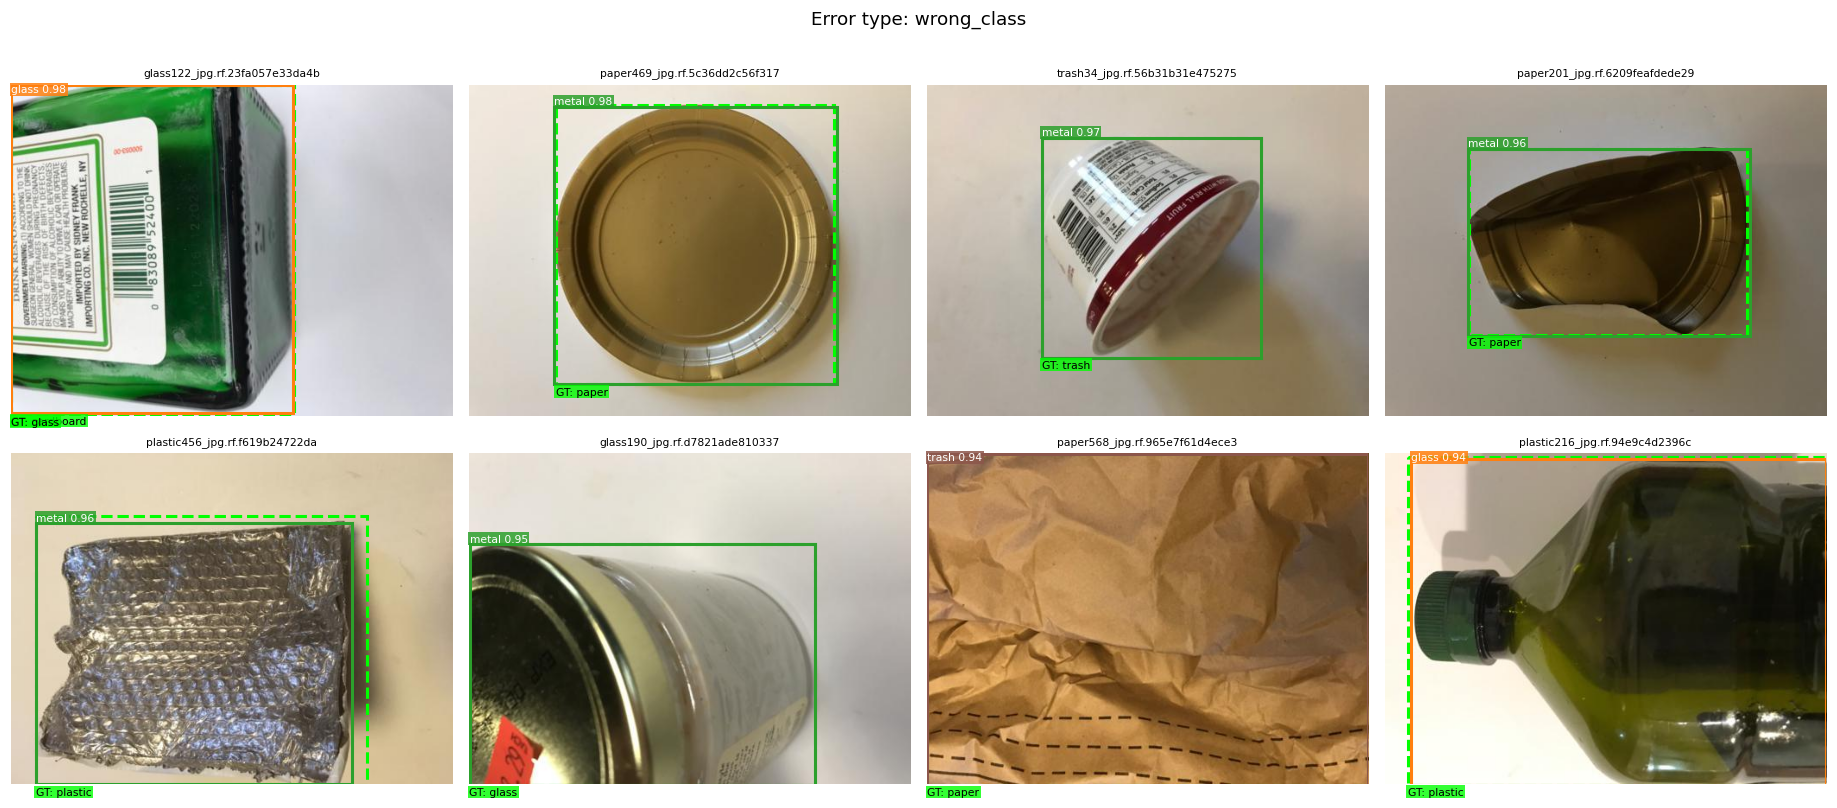

,image_id,gt_name,pred_name,score,iou
0,107,cardboard,glass,0.985,0.992
1,15,paper,metal,0.979,0.977
2,60,trash,metal,0.971,0.996
3,161,paper,metal,0.965,0.981
4,223,plastic,metal,0.957,0.928
5,131,glass,metal,0.945,0.997
6,97,paper,trash,0.940,0.998
7,227,plastic,glass,0.940,0.983


In [18]:
# Error cases, most confident mistakes first
def show_errors(kind, n=8, cols=4):
    if not len(errs) or not (errs["type"] == kind).any():
        print(f"No '{kind}' cases."); return
    sub = errs[errs["type"] == kind].sort_values("score", ascending=False).drop_duplicates("image_id").head(n)
    draw_cases("test", sub["image_id"].tolist(), BEST_THR, cols=cols, title=f"Error type: {kind}", savename=f"errors_{kind}")
    display(sub[["image_id", "gt_name", "pred_name", "score", "iou"]].round(3).reset_index(drop=True))

show_errors("wrong_class")

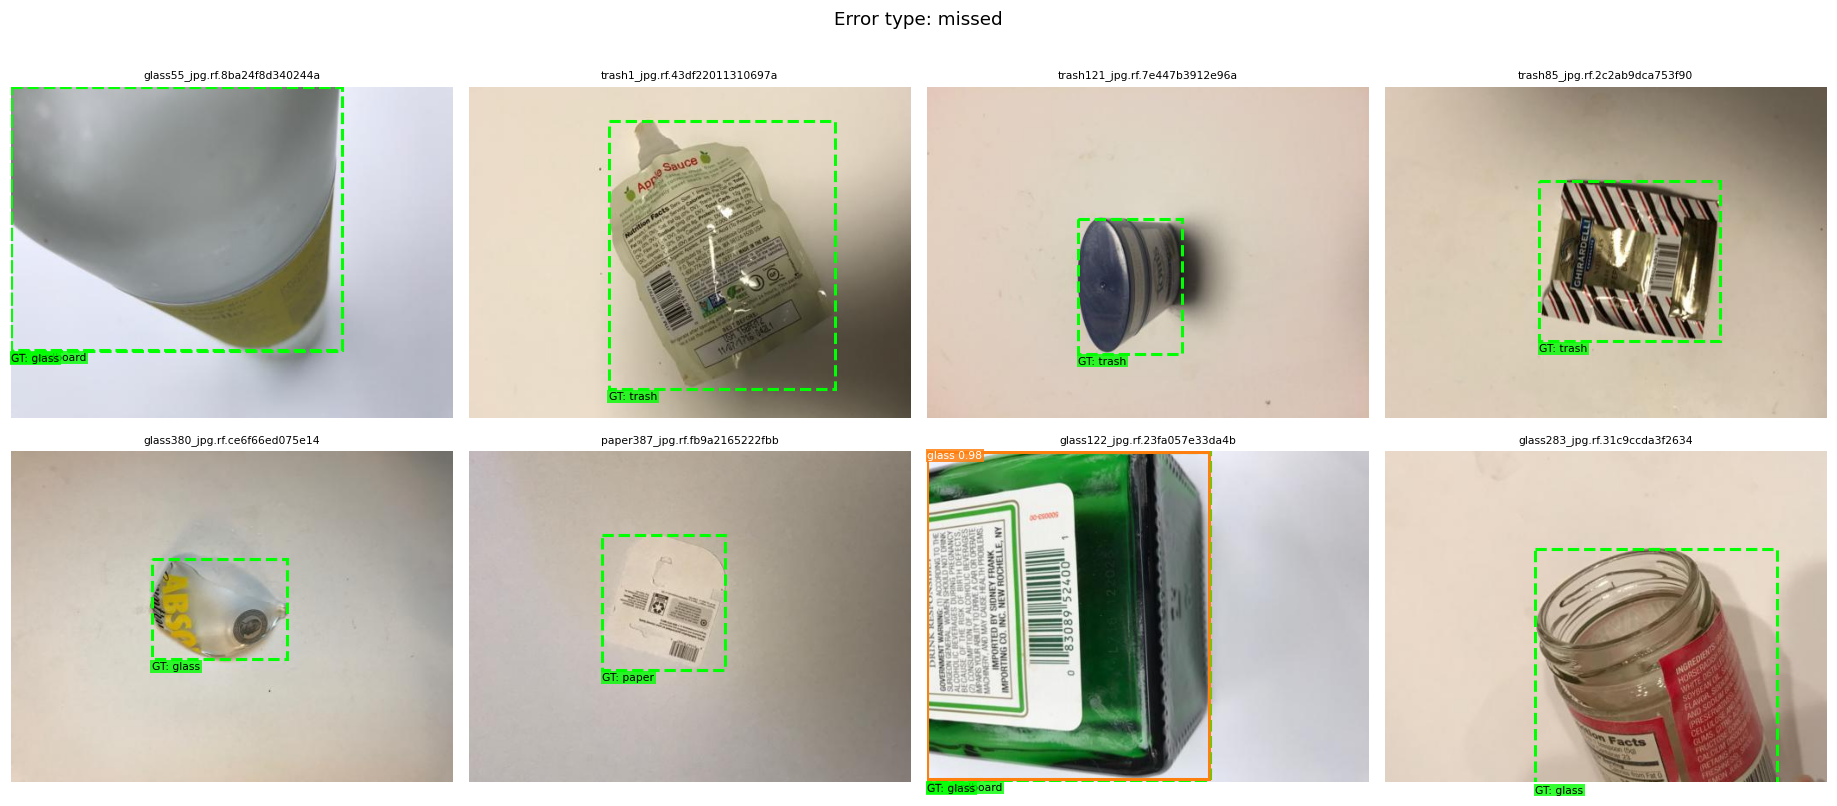

,image_id,gt_name,pred_name,score,iou
0,39,cardboard,-,0.0,0.00
1,50,trash,-,0.0,0.00
2,85,trash,-,0.0,0.00
3,90,trash,-,0.0,0.00
4,94,glass,-,0.0,0.00
5,95,paper,-,0.0,0.00
6,107,glass,-,0.0,0.99
7,120,glass,-,0.0,0.00


In [19]:
show_errors('missed')

In [20]:
show_errors('false_positive')

No 'false_positive' cases.


### Does object size or localization quality explain the errors?

If errors cluster on small boxes, or if even correct detections have loose boxes, that points to localization or resolution limits rather than class confusion.

**How to read it.** If recall is similar across the three size groups, size is not the cause of errors. If the IoU histogram is mostly well above the threshold line, localization is good and errors come from classification or missing detections.

Recall by object size (share of image area):


,objects,recall,median_rel_area
size_group,,,
small third,127,0.882,0.276
medium third,127,0.890,0.551
large third,128,0.961,0.943


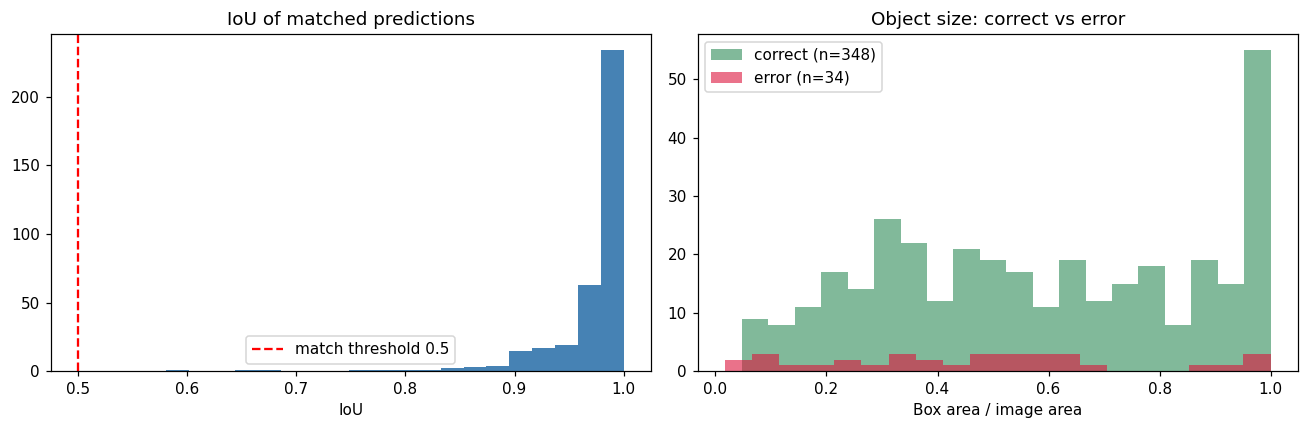

Mean IoU of matched boxes: 0.971
Recall per class:


,recall
class,
cardboard,0.945
glass,0.910
metal,0.926
paper,0.919
plastic,0.904
trash,0.733


In [21]:
gr = RES["gt_rows"].copy()
gr["class"] = gr["gt"].map(lambda i: CLASS_NAMES[i])
gr["correct"] = gr["outcome"] == "correct"

# Recall by object-size tercile
gr["size_group"] = pd.qcut(gr["rel_area"], 3, labels=["small third", "medium third", "large third"])
size_tbl = gr.groupby("size_group", observed=True).agg(objects=("correct", "size"), recall=("correct", "mean"),
                                                         median_rel_area=("rel_area", "median"))
print("Recall by object size (share of image area):")
display(size_tbl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(RES["gt_rows"].query("outcome != 'missed'")["iou"], bins=20, color="steelblue")
axes[0].axvline(IOU_THR, color="red", ls="--", label=f"match threshold {IOU_THR}")
axes[0].set_title("IoU of matched predictions"); axes[0].set_xlabel("IoU"); axes[0].legend()
for flag, lab, c in [(True, "correct", "seagreen"), (False, "error", "crimson")]:
    d = gr[gr["correct"] == flag]["rel_area"]
    if len(d): axes[1].hist(d, bins=20, alpha=.6, label=f"{lab} (n={len(d)})", color=c)
axes[1].set_title("Object size: correct vs error"); axes[1].set_xlabel("Box area / image area"); axes[1].legend()
plt.tight_layout(); savefig("iou_and_size"); plt.show()

print(f"Mean IoU of matched boxes: {RES['mean_iou']:.3f}")
print("Recall per class:"); display(gr.groupby("class")["correct"].mean().round(3).to_frame("recall"))

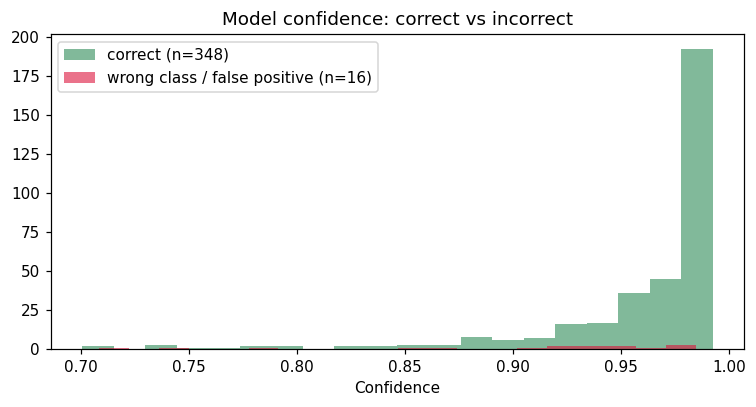

In [22]:
# Confidence of correct detections vs mistakes
fig, ax = plt.subplots(figsize=(7, 3.8))
ok = RES["gt_rows"].query("outcome == 'correct'")["score"]
ax.hist(ok, bins=20, alpha=.6, label=f"correct (n={len(ok)})", color="seagreen")
if len(errs):
    bad = errs[errs["type"].isin(["wrong_class", "false_positive"])]["score"]
    if len(bad): ax.hist(bad, bins=20, alpha=.6, label=f"wrong class / false positive (n={len(bad)})", color="crimson")
ax.set_xlabel("Confidence"); ax.set_title("Model confidence: correct vs incorrect"); ax.legend()
plt.tight_layout(); savefig("confidence_hist"); plt.show()

### Notes for writing the discussion

Use the tables and figures above to answer these. Everything below depends on **your** numbers, so fill it in after you run the notebook.

- **Strengths:** which classes have the highest AP and recall, and what they look like (large, distinctive objects?).
- **Weaknesses:** the lowest-recall class and the top entry in the confusion table. Open the saved images for that pair and describe what is visually similar.
- **Missed objects:** do they cluster in a class or size group? Do they look occluded, transparent (glass, clear plastic), or low contrast?
- **False positives:** are they duplicates of a correct box (IoU with a true box is high) or detections of nothing (IoU near 0)?
- **The `trash` class:** it is a catch-all with few test samples (15 boxes in this dataset), so its precision and recall can swing a lot from one or two images. Say this explicitly.
- **Localization:** if mean IoU is high but mAP@0.5:0.95 is much lower than mAP@0.5, boxes are found but not tightly fitted.
- **Dataset limitation:** every image is a single object on a plain background at 512x384, so these results will not transfer to cluttered scenes.

## 8. Inference speed and saving the results

**Notes.** Latency depends on the runtime. Report the GPU used (for example Colab T4) with the number. The first predictions after loading are slower, which is why a short warm-up runs first.

In [23]:
# Latency on test images (batch of 1), after a short warm-up
files = [GT["test"][i]["file"] for i in list(GT["test"])[:60]]
imgs = [Image.open(f"{DATA_DIR}/test/{f}").convert("RGB") for f in files]
for im in imgs[:5]: model.predict(im, threshold=0.5)
t0 = time.time()
for im in imgs[5:]: model.predict(im, threshold=0.5)
ms = (time.time() - t0) / len(imgs[5:]) * 1000
print(f"Average latency: {ms:.1f} ms/image ({1000/ms:.1f} images/s) on this runtime")

Average latency: 659.3 ms/image (1.5 images/s) on this runtime


In [24]:
results = dict(
    run_name=RUN_NAME, checkpoint=CKPT, iou_threshold=IOU_THR, confidence_threshold=BEST_THR,
    test=dict(
        accuracy_after_matching=RES["cls_accuracy"], precision=RES["precision"], recall=RES["recall"], f1=RES["f1"],
        mean_iou=RES["mean_iou"], TP=RES["TP"], FP=RES["FP"], FN=RES["FN"], n_gt=RES["n_gt"],
        mAP_50=MAP["mAP_50"], mAP_75=MAP["mAP_75"], mAP_50_95=MAP["mAP_50_95"], AR_100=MAP["AR_100"],
    ),
    test_at_conf_0_5=dict(accuracy_after_matching=RES_05["cls_accuracy"], precision=RES_05["precision"],
                          recall=RES_05["recall"], f1=RES_05["f1"]),
    latency_ms_per_image=ms,
)
with open(f"{RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(results, f, indent=2)
per_class.to_csv(f"{RESULTS_DIR}/per_class_results.csv", index=False)
sweep_val.to_csv(f"{RESULTS_DIR}/valid_threshold_sweep.csv", index=False)
if len(errs): errs.drop(columns=["gi", "pj"]).to_csv(f"{RESULTS_DIR}/test_errors.csv", index=False)
print(json.dumps(results, indent=2))
print("\nSaved results and figures to", RESULTS_DIR)

{
  "run_name": "exp_a_baseline_noaug",
  "checkpoint": "/content/drive/MyDrive/rf-detr-trash/runs/exp_a_baseline_noaug/checkpoint_best_total.pth",
  "iou_threshold": 0.5,
  "confidence_threshold": 0.7,
  "test": {
    "accuracy_after_matching": 0.9560439560439561,
    "precision": 0.9560439560439561,
    "recall": 0.9109947643979057,
    "f1": 0.932975871313673,
    "mean_iou": 0.9708900510028093,
    "TP": 348,
    "FP": 16,
    "FN": 34,
    "n_gt": 382,
    "mAP_50": 0.9531675889202443,
    "mAP_75": 0.9417329061507501,
    "mAP_50_95": 0.9236327221516392,
    "AR_100": 0.9865802305259376
  },
  "test_at_conf_0_5": {
    "accuracy_after_matching": 0.9389920424403183,
    "precision": 0.9267015706806283,
    "recall": 0.9267015706806283,
    "f1": 0.9267015706806283
  },
  "latency_ms_per_image": 659.339393268932
}

Saved results and figures to /content/drive/MyDrive/rf-detr-trash/results/exp_a_baseline_noaug


## 9. Summary of results

This cell writes a short summary from the numbers computed above, so the text always matches the run. Copy it into Section 4 of the report and extend it with your own observations.

In [25]:
worst = per_class.sort_values("AP_50").iloc[0]
best  = per_class.sort_values("AP_50").iloc[-1]
print(f"Model: {type(model).__name__}, run {RUN_NAME}, evaluated on {len(GT['test'])} test images ({RES['n_gt']} boxes).")
print(f"Threshold-free: mAP@0.5 = {MAP['mAP_50']:.3f}, mAP@0.5:0.95 = {MAP['mAP_50_95']:.3f}.")
print(f"At confidence >= {BEST_THR} (chosen on validation): accuracy {RES['cls_accuracy']:.3f}, precision {RES['precision']:.3f}, "
      f"recall {RES['recall']:.3f}, F1 {RES['f1']:.3f}, mean IoU {RES['mean_iou']:.3f}.")
print(f"Best class by AP@0.5: {best['class']} ({best['AP_50']:.3f}). Weakest class: {worst['class']} ({worst['AP_50']:.3f}, {int(worst['support'])} test boxes).")
if len(errs):
    print("Errors by type:", errs["type"].value_counts().to_dict())
print(f"Inference speed: {ms:.0f} ms per image.")

Model: RFDETRNano, run exp_a_baseline_noaug, evaluated on 377 test images (382 boxes).
Threshold-free: mAP@0.5 = 0.953, mAP@0.5:0.95 = 0.924.
At confidence >= 0.7 (chosen on validation): accuracy 0.956, precision 0.956, recall 0.911, F1 0.933, mean IoU 0.971.
Best class by AP@0.5: glass (0.985). Weakest class: trash (0.852, 15 test boxes).
Errors by type: {'missed': 18, 'wrong_class': 16}
Inference speed: 659 ms per image.
